# Sentinel: multi-agent AML transaction monitoring

> **Draft for analyst review, not legal, compliance or regulatory advice. Synthetic data only.**

Sentinel helps an AML analyst in a UK bank's financial-crime team:

1. **Rules** (tier 1) score every transaction and clear most of them with no LLM call.
2. **Agents** (tier 2): a Deep Agents supervisor investigates the rest, delegating in parallel to four specialists:
   pattern analyst, KYC & precedent, fund-flow (the one audited cross-customer tool) and SAR writer.
3. **A human** (tier 3) decides when the agents aren't confident. The analyst's note becomes a **precedent** with an
   expiry date. Safeguards are code, not prompts: hard red flags beat precedents, and precedents must match scope.

Everything is traced to LangSmith and measured against a rules-only baseline. The code is in `agents.py`.
Set `REPLAY=1` before starting the kernel to replay a recorded live run (shown in the banner below).

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path().resolve().parent))  # the sentinel_aml_agent folder

from utils import db, replay

replay.enable()
from utils.demo import Demo, eval_tables, md, monitoring

demo = Demo()
md(f"**{replay.replay_banner()}** · {demo.seeded} old analyst precedents loaded into long-term memory.")

**LIVE, recording model responses for replay.** · 3 old analyst precedents loaded into long-term memory.

## 1. Normal traffic: rules first
Every transaction from 1 to 5 October. The rules clear almost all of them in milliseconds. The few they flag
(first payments to a new supplier that look like pass-through) go to the agents, who find the legitimate
explanation, so these false alerts never reach an analyst as alerts. Where the agents aren't sure, they ask for a
review instead of guessing.

In [2]:
run = demo.stream("2026-10-01", "2026-10-06", "Stream: 1-5 October")

**Stream: 1-5 October**: 122/122 transactions · 117 cleared by rules (no LLM) · 5 investigated by agents

🧑‍⚖️ **Review requested** for `TX-000076` (mule network suspected but not confirmed by the graph check; it involves other customers, so a human decides (DEC-015)). This background case has no analyst in the demo, so the agents' decision (**clear**) stands, as in the starter. In production it would wait in the queue.

🧑‍⚖️ **Review requested** for `TX-000078` (the agents' confidence (0.64) is below 0.7). This background case has no analyst in the demo, so the agents' decision (**clear**) stands, as in the starter. In production it would wait in the queue.

🧑‍⚖️ **Review requested** for `TX-000077` (the agents' confidence (0.65) is below 0.7). This background case has no analyst in the demo, so the agents' decision (**clear**) stands, as in the starter. In production it would wait in the queue.

**122 transactions**: 117 cleared by rules (95.9%) with no LLM call; 5 investigated (69 model calls).

✅ **TX-000076** Adam Jarvis · £2,100 faster payment · **CLEAR** by human · TX-000076 is a £2,100 stock-referenced payment to first-time supplier EXT-SUP-0116, but the only identified preceding credit is TX-000052, a £426.84 cash takings deposit; the payment therefore is not explained as a direc

✅ **TX-000073** Erin Young · £2,100 faster payment · **CLEAR** by agent · TX-000073 is a £2,100 stock-referenced payment to a first-time wholesale supplier, 20 hours 49 minutes after TX-000056, a £677.03 cash deposit marked 'Takings'; the deposit alone cannot fund the payment. The cash fits th

✅ **TX-000078** Hannah Grant · £1,400 faster payment · **CLEAR** by human · TX-000078 paid £1,400 to new wholesale supplier EXT-SUP-0129 for 'Stock' after TX-000066 deposited £540.56 in cash 17 hours earlier; that deposit is £859.44 short of the payment and is consistent with the customer's expe

✅ **TX-000072** Arthur Turner · £1,400 faster payment · **CLEAR** by agent · TX-000072 is a £1,400 stock-referenced payment to a new wholesale supplier following TX-000060, a £419.76 cash deposit consistent with the takeaway owner's takings; the outgoing payment exceeds that recent credit rather 

✅ **TX-000077** Henry Kaur · £4,200 faster payment · **CLEAR** by human · TX-000077 is a £4,200 payment to a new wholesale-supplier counterparty marked 'Stock'; TX-000062 is the only observed preceding credit, a £1,026.85 cash deposit marked 'Takings', so the payment exceeds that credit and th

## 2. Structuring
Daniel Hughes, a market trader, deposits four lots of £9,500 cash at three branches in 48 hours. Each one is just
under the bank's £10,000 cash-monitoring threshold, so each looks fine alone. The 3rd already raises an alert; the
4th has the most evidence.

In [3]:
deposits = sorted(db.query("transactions", user_id="CUS-0001", txn_type="cash_deposit"), key=lambda t: t["timestamp"])
daniel = [t["transaction_id"] for t in deposits if "2026-10-06" <= t["timestamp"] < "2026-10-09"]
run = demo.case(daniel)

✅ **TX-000131** Daniel Hughes · £9,500 cash deposit · **CLEAR** by rules
- Rules: score 20 · cash deposit £9,500 just under the £10,000 threshold
- Verdict: none · risk 20 · confidence None
- Reason: cleared by rules

✅ **TX-000149** Daniel Hughes · £9,500 cash deposit · **CLEAR** by rules
- Rules: score 20 · cash deposit £9,500 just under the £10,000 threshold
- Verdict: none · risk 20 · confidence None
- Reason: cleared by rules

🚨 **TX-000159** Daniel Hughes · £9,500 cash deposit · **ESCALATE** by agent
- Rules: score 85 · cash deposit £9,500 just under the £10,000 threshold; 3 near-threshold cash deposits in 72h at 3 branches; £28,500 cash in 48h vs £12,000 expected per month
- Supervisor delegated to: pattern-analyst, kyc-precedent, sar-writer · 12 model calls · 26.3s · [trace](https://smith.langchain.com/o/86028173-97ea-4fe1-8d7d-78740a88330b/projects/p/558e791f-4ed5-418b-b4b4-b6c25ddaac7c/r/03f73900-eeae-4470-9cab-d2bc3463ddde)
- Verdict: structuring · risk 82 · confidence 0.82
- Reason: TX-000131, TX-000149 and TX-000159 were identical £9,500 cash deposits at three different branches within 25.5 hours, totaling £28,500 against expected monthly cash of £12,000. Market-trader cash takings are plausible but unverified and do not explain the repeated near-threshold amounts across branches; no applicable precedent or hard screening flag was found.

🚨 **TX-000167** Daniel Hughes · £9,500 cash deposit · **ESCALATE** by agent
- Rules: score 85 · cash deposit £9,500 just under the £10,000 threshold; 4 near-threshold cash deposits in 72h at 3 branches; £38,000 cash in 48h vs £12,000 expected per month
- Supervisor delegated to: pattern-analyst, kyc-precedent, sar-writer · 12 model calls · 27.4s · [trace](https://smith.langchain.com/o/86028173-97ea-4fe1-8d7d-78740a88330b/projects/p/558e791f-4ed5-418b-b4b4-b6c25ddaac7c/r/a7505ae2-3009-4dd8-af40-236a605f7857)
- Verdict: structuring · risk 87 · confidence 0.84
- Reason: TX-000131, TX-000149, TX-000159 and TX-000167 are four £9,500 cash deposits at three branches over 47 hours 18 minutes, totaling £38,000 against expected monthly cash of £12,000. Although the customer's market-trader occupation could entail cash takings, no evidence verifies that explanation for the repeated near-£10,000 deposits; KYC found no hard flags or applicable precedents.

## 3. Unsure, so ask a human
Sophie Clarke receives £18,000, about five times her monthly salary, from a counterparty she's never been paid by.
It could be fraud, a bonus or a property sale. If the agents aren't confident, the graph pauses (`interrupt()`) and
the analyst panel appears. **Type a note and click Clear or Escalate.**

In [4]:
sophie_1 = "TX-000254"
review = demo.start_review(sophie_1)
demo.panel(review)

### 🧑‍⚖️ Analyst review needed: `TX-000254`
- **Agents' view:** clear · risk 38 · confidence 0.62 (after checks 0.5)
- **Why you're being asked:** risk score 38 is in the grey zone (30-69)
- **Evidence:** TX-000254 is a £18,000 incoming payment from first-time counterparty EXT-0102, 5.1× expected monthly credits, but its 'Annual bonus' reference plausibly explains the one-off credit and remains unverified. The 30-day history shows only TX-000005 (£980 rent) as an outgoing transfer, with no apparent onward or return flow; KYC screening found no hard flags or applicable precedents.
- **Rules flagged:** credit £18,000 is 5.1× expected monthly credits; first payment with counterparty EXT-0102
- **Precedents:** valid none · expired none

In [5]:
# Only needed when the notebook runs unattended (nobody clicked above): the scripted analyst answers, labelled.
demo.ensure_answered(review, sophie_1)

*No click recorded in this run of the notebook, so the scripted analyst answers.*

🧑‍⚖️ **Asked a human** about `TX-000254` because: risk score 38 is in the grey zone (30-69). *Scripted analyst* (reviewer_answers.jsonl): **clear**, "Annual bonus — employer verified via payslip"

✅ **TX-000254** Sophie Clarke · £18,000 faster payment · **CLEAR** by human
- Rules: score 45 · credit £18,000 is 5.1× expected monthly credits; first payment with counterparty EXT-0102
- Supervisor delegated to: kyc-precedent, pattern-analyst · 11 model calls · 19.4s · [trace](https://smith.langchain.com/o/86028173-97ea-4fe1-8d7d-78740a88330b/projects/p/558e791f-4ed5-418b-b4b4-b6c25ddaac7c/r/9eb85104-f990-44f2-afd0-717e3ff52010)
- Verdict: anomalous_credit · risk 38 · confidence 0.5
- Analyst note → saved as a precedent: "Annual bonus — employer verified via payslip"
- Reason: TX-000254 is a £18,000 incoming payment from first-time counterparty EXT-0102, 5.1× expected monthly credits, but its 'Annual bonus' reference plausibly explains the one-off credit and remains unverified. The 30-day history shows only TX-000005 (£980 rent) as an outgoing transfer, with no apparent onward or return flow; KYC screening found no hard flags or applicable precedents.

## 4. Ten months later: the precedent pays off
Same employer, a similar amount, August 2027. The agents find the analyst's precedent (same customer, same
counterparty, same pattern, not expired), and nobody has to investigate it twice.

In [6]:
run = demo.case(["TX-001130"])

🧑‍⚖️ **Review requested** for `TX-001130` (the agents' confidence (0.68) is below 0.7). This background case has no analyst in the demo, so the agents' decision (**clear**) stands, as in the starter. In production it would wait in the queue.

✅ **TX-001130** Sophie Clarke · £19,200 faster payment · **CLEAR** by human
- Rules: score 35 · credit £19,200 is 5.5× expected monthly credits
- Supervisor delegated to: kyc-precedent, pattern-analyst · 12 model calls · 18.7s · [trace](https://smith.langchain.com/o/86028173-97ea-4fe1-8d7d-78740a88330b/projects/p/558e791f-4ed5-418b-b4b4-b6c25ddaac7c/r/ab8423ee-6bd8-4cac-9b08-2217624c3dc2)
- Verdict: anomalous_credit · risk 25 · confidence 0.68
- **Precedent relied on:** 2026-10-14 "Annual bonus — employer verified via payslip", valid until 2027-10-14. Hard red flags: none.
- Reason: TX-001130 is a £19,200 credit from EXT-0102 marked 'Annual bonus', 5.5× expected monthly credits; the bonus explanation is plausible but unverified, and the 90-day lookback shows no onward transfer or cash deposits. The valid EXT-0102:anomalous_credit precedent supports clearing this same-counterparty pattern, and KYC screening identified no hard flags.

## 5. Money-mule ring, and a safeguard override
Five low-risk accounts receive small transfers and forward almost everything to **Northgate Trading Ltd**, a new
business account, within hours. No single customer looks suspicious. The 4th forward goes to a human (the ring
isn't confirmed yet); at the 5th, the graph check confirms the ring. Then Liam Walsh receives money from his
"flatmate", which an analyst cleared months ago. **That precedent must not let him through.**

In [7]:
run = demo.case(["TX-000762", "TX-000770", "TX-000779"])

🧑‍⚖️ **Asked a human** about `TX-000762` because: mule network suspected but not confirmed by the graph check; it involves other customers, so a human decides (DEC-015). *Scripted analyst* (reviewer_answers.jsonl): **escalate**, "Rapid pass-through to a new business account; possible mule activity."

🚨 **TX-000762** Amira Khan · £1,489 internal transfer · **ESCALATE** by human
- Rules: score 40 · first payment with counterparty ACC-0050; sends on £1,489 of £1,568 received in the last 24h
- Supervisor delegated to: kyc-precedent, pattern-analyst, fund-flow, sar-writer · 17 model calls · 33.1s · [trace](https://smith.langchain.com/o/86028173-97ea-4fe1-8d7d-78740a88330b/projects/p/558e791f-4ed5-418b-b4b4-b6c25ddaac7c/r/ad684532-3a6f-441a-9825-3979a6a71468)
- Verdict: mule_fan_in · risk 76 · confidence 0.5
- Analyst note → saved as a precedent: "Rapid pass-through to a new business account; possible mule activity."
- Reason: TX-000759 (£529.95), TX-000760 (£452.90) and TX-000761 (£584.72) arrived from three individuals within 1 hour 40 minutes; TX-000762 forwarded £1,489.19 (about 95% of their £1,567.57 total) to ACC-0050 three hours after the final credit. This rapid fan-in/pass-through is inconsistent with the student's £900 expected monthly credits, although personal repayments or rent and an invoice payment remain unverified alternatives; fund-flow did not confirm a ring, KYC found no screening hits, and no applicable precedents were found.

🚨 **TX-000770** Josh Patel · £1,810 internal transfer · **ESCALATE** by agent
- Rules: score 60 · first payment with counterparty ACC-0050; sends on £1,810 of £1,906 received in the last 24h; account is a feeder in a fan-in ring into ACC-0050 confirmed at 2026-11-11T14:00 (network check)
- Supervisor delegated to: kyc-precedent, pattern-analyst, fund-flow, sar-writer · 15 model calls · 32.5s · [trace](https://smith.langchain.com/o/86028173-97ea-4fe1-8d7d-78740a88330b/projects/p/558e791f-4ed5-418b-b4b4-b6c25ddaac7c/r/f332c5b1-7ad1-4b3c-94d7-8c6e199bd4e1)
- Verdict: mule_fan_in · risk 96 · confidence 0.96
- **Hard flags:** confirmed fan-in ring member (feeder, collector ACC-0050, confirmed 2026-11-11T14:00)
- Reason: TX-000764 (£408.92), TX-000766 (£754.19) and TX-000768 (£742.46) brought in £1,905.57 from three individuals on 2026-11-11; TX-000770 forwarded £1,810.29 (~95%) to ACC-0050 hours later. Fund-flow confirmed a fan-in ring with ACC-0050 as collector (hard flag), and the 'Invoice' reference does not explain the incoming payments; no applicable precedent or screening hit was found.

🚨 **TX-000779** Liam Walsh · £782 faster payment · **ESCALATE** by agent
- Rules: score 60 · account is a feeder in a fan-in ring into ACC-0050 confirmed at 2026-11-11T14:00 (network check)
- Supervisor delegated to: kyc-precedent, fund-flow, sar-writer · 13 model calls · 31.3s · [trace](https://smith.langchain.com/o/86028173-97ea-4fe1-8d7d-78740a88330b/projects/p/558e791f-4ed5-418b-b4b4-b6c25ddaac7c/r/54758460-c87b-41ec-acb1-306a2109023e)
- Verdict: mule_fan_in · risk 95 · confidence 0.95
- **Hard flags:** confirmed fan-in ring member (feeder, collector ACC-0050, confirmed 2026-11-11T14:00)
- **Precedent found → OVERRIDDEN:** "Transfers from flatmates for rent" (EXT-FLAT-0040:mule_fan_in). Reason: hard red flag: confirmed fan-in ring member (feeder, collector ACC-0050, confirmed 2026-11-11T14:00)
- Reason: TX-000779 is a GBP 781.76 incoming payment from EXT-FLAT-0040 ('Rent') on 2026-11-12, to Liam Walsh's ACC-0040; the fund-flow check confirms ACC-0040 is a feeder in a fan-in ring collecting at ACC-0050, with a 0.95 pass-through ratio. This confirmed ring is a hard flag and outweighs the applicable EXT-FLAT-0040:mule_fan_in precedent despite the customer's low-risk KYC and no screening hits.

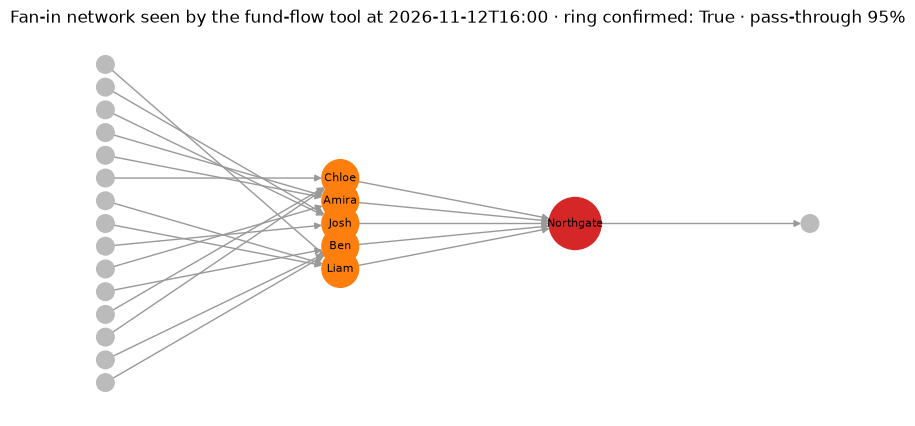

In [8]:
demo.network_graph("ACC-0050", "2026-11-12T16:00")

## 6. Does it work? Evals in LangSmith
Numbers from real experiment runs, loaded from file (never run live). The baseline is the same tier 1 on its own.

In [9]:
eval_tables()

**Loaded from `results/eval_summary.json`** (updated 2026-11-25T09:01:40+00:00, model `openai:gpt-6-sol`). Synthetic benchmark generated by data/generate.py. Rules tuned on dev only; headline numbers are from the test split. Human answers in the 'sentinel' runs are scripted from reviewer_answers.jsonl.

### Headline: held-out test world (950 transactions, 15 planted alerts)
| | Rules only | Sentinel |
|---|---|---|
| False positives | 30 | **2** (-93%) |
| Alert precision | 33% | **88%** |
| Recall on planted alerts | 100% | **100%** |
| Decision accuracy · score alignment · review routing (starter evaluators) | 0.968 · 0.938 · 0.990 | 0.993 · 0.942 · 0.975 |
| Human reviews, month 1 → month 2 (repeat cases planted in the data) | – | 28 → 6 |
| Transactions reaching an LLM | 0% | 4.7% |
| Per investigation: model calls · tokens · median seconds | – | 12.1 · 36,243 · 22s |

### Coverage: 8 evaluation categories
| Category | Dataset | Evaluators | Rules only | Sentinel |
|---|---|---|---|---|
| 1. Detection quality | benchmark | `false_positives`, `false_positive_rate`, `alert_precision`, `recall_planted` | 30 · 3.2% · 33.3% · 100.0% | 2 · 0.2% · 88.2% · 100.0% |
| 2. Risk calibration | benchmark | `score_alignment_eval` | 93.8% | 94.2% |
| 3. Human-in-the-loop routing | benchmark | `review_routing_eval`, `human_review_rate`, `reviews_month1`, `reviews_month2` | 99.0% · 0.0% · 0 · 0 | 97.5% · 3.6% · 28 · 6 |
| 4. Memory safeguards | scenarios | `precedent_used_when_valid`, `no_reliance_on_invalid_precedent`, `hard_flag_overrides_precedent` | 0.0% · – · 0.0% | 100.0% · 100.0% · 100.0% |
| 5. Agent behaviour | scenarios | `kyc_called_every_time`, `record_decision_once`, `specialists_match_rule_reasons` | – · – · – | 100.0% · 100.0% · 100.0% |
| 6. SAR quality | scenarios | `sar_grounded`, `sar_written_for_escalations` | – · – | 100.0% · 100.0% |
| 7. Efficiency | benchmark | `llm_share`, `model_calls_per_investigation`, `tokens_per_investigation`, `p50_seconds_per_investigation` | 0.0% · 0 · 0 · 0 | 4.7% · 12.1 · 36,243 · 21.9 |
| 8. Privacy and scope | scenarios | `network_calls_audited`, `network_returns_account_ids_only` | – · – | 100.0% · 100.0% |
| 6b. SAR completeness (LLM judge) | online | `sar_complete` | – | see monitoring below |

**Not covered yet:** real or public AML data, adversarial inputs (e.g. prompt injection through payment references), fairness across customer groups, production load, analyst usability.

**LangSmith experiments:** `rules-only-dev-7bd87a6c` · `sentinel-dev-bd3c4b44` · `rules-only-test-b41d4cd7` · `sentinel-test-479275d9` · `rules-only-scenarios-0820df3b` · `sentinel-scenarios-c3a39b51`

## 7. After go-live: monitor and govern
An online evaluator in LangSmith judges every SAR draft as it's written, and an annotation queue puts human-decided
cases and a sample of the agents' own decisions in front of an analyst.

In [10]:
monitoring()

**Online evaluator `sar_complete`:** not scoring yet (50 `sar-writer` runs in the project). Set it up with `evals/online_evaluators.md`.

**Annotation queue:** created; no reviews collected yet (`scripts/annotation_queue.py --collect`).

## 8. The hand-off: a SAR draft
Built by the SAR writer from the evidence the investigation gathered, nothing else. Every transaction it cites was
checked in code against the database.

In [11]:
demo.sar("TX-000167")

### SAR draft · Daniel Hughes, CUS-0001 · structuring
> **Draft for analyst review, not legal, compliance or regulatory advice. Synthetic data only.**

**Timeline**
- 2026-10-06 09:40 — TX-000131: £9,500 cash deposit at Leeds Briggate.
- 2026-10-06 16:10 — TX-000149: £9,500 cash deposit at Wakefield Westgate.
- 2026-10-07 11:10 — TX-000159: £9,500 cash deposit at Bradford Broadway.
- 2026-10-08 08:58 — TX-000167: £9,500 cash deposit at Leeds Briggate; recorded escalation with structuring risk score 87 and confidence .84.

**Evidence**
- TX-000131, TX-000149, TX-000159 and TX-000167 are four identical £9,500 cash deposits, each just below £10,000, across three branches in 47 hours 18 minutes, totaling £38,000.
- TX-000131, TX-000149, TX-000159 and TX-000167 total £38,000, over three times the expected monthly cash of £12,000.
- TX-000167: recorded escalation for structuring risk, score 87, confidence .84.

**Narrative.** Four identical cash deposits just below £10,000 across three branches in 47 hours 18 minutes raise a structuring concern. Their £38,000 total exceeds three times the customer's expected monthly cash of £12,000. Cash takings are plausible for an individual market trader, but have not been verified; KYC reports no screening hits, PEP or sanctions flags, or other hard flags. The analyst should check whether the deposits reflect documented market-trader takings and assess the activity against the stated cash expectations; no prior escalation is visible in the supplied records.

**Precedents.** No applicable, expired or overridden precedents were reported.

*Draft for analyst review, not legal, compliance or regulatory advice. Synthetic data only.*

In [12]:
md(f"**Session:** {demo.totals['transactions']} transactions · {demo.totals['rules']} cleared by rules · "
   f"{len(demo.investigations)} investigations · {demo.totals['escalate']} escalated · "
   f"{demo.totals['model_calls']} model calls. {replay.replay_banner()}")

**Session:** 131 transactions · 119 cleared by rules · 12 investigations · 5 escalated · 161 model calls. LIVE, recording model responses for replay.